# Homework 1: Text Classification
## Due Date: Wed, Sep 16, 2026, 11:59 PM EST
- **Overview**: For this assignment, we’ll be building a text classifier. The goal of our text classifer will be to distinguish between words that are simple and words that are complex. Example simple words are `heard`, `sat`, and `town`, and example complex words are `abdicate`, `detained`, and `vintners`. Distinguishing between simple and complex words is the first step in a larger NLP task called text simplification, which aims to replace complex words with simpler synonyms. Text simplification is potentially useful for re-writing texts so that they can be more easily understood by younger readers, people learning English as a second language, or people with learning disabilities.

- **Learning goals**:
    - Understand an important class of NLP evaluation methods (precision, recall and F1), and implement them yourself.
    - Employ common experimental design practices in NLP. Split the annotated data into training/development/test sets, implement simple baselines to determine how difficult the task is, and experiment with a range of features and models.
    - Get an introduction to `sklearn`, an excellent machine learning Python package.

- **Data**: We will provide you with training and development data that has been manually labeled. We will also give you a test set without labels. You will build a classifier to predict the labels on our test set. You can upload your classifier’s predictions to Gradescope. We will score its predictions and maintain a leaderboard showing whose classifier has the best performance.

## Recommended Readings
- [Naive Bayes Classification and Sentiment](https://web.stanford.edu/~jurafsky/slp3/4.pdf) Dan Jurafsky and James H. Martin. Speech and Language Processing (3rd edition draft).
- [Logistic Regression](https://web.stanford.edu/~jurafsky/slp3/5.pdf) Dan Jurafsky and James H. Martin. Speech and Language Processing (3rd edition draft) .
- [Problems in Current Text Simplification Research: New Data Can Help](http://www.cis.upenn.edu/~ccb/publications/new-data-for-text-simplification.pdf) Wei Xu, Chris Callison-Burch, and Courtney Napoles. TACL 2015.
- [Comparison of Techniques to Automatically Identify Complex Words](http://aclweb.org/anthology/P/P13/P13-3015.pdf) Matthew Shardlow. ACL 2013.
- [SemEval 2016 Task 11: Complex Word Identification](https://www.researchgate.net/profile/Gustavo_Paetzold/publication/305334627_SemEval_2016_Task_11_Complex_Word_Identification/links/57bab70a08ae14f440bd9722/SemEval-2016-Task-11-Complex-Word-Identification.pdf) Gustavo Paetzold and Lucia Specia. ACL 2016.

## Setup 1: PennGrader Setup

In [18]:
## DO NOT CHANGE ANYTHING, JUST RUN
%%capture
!pip install penngrader-client dill

In [19]:
%%writefile notebook-config.yaml

grader_api_url: "https://yj0vsrf8l4.execute-api.us-east-1.amazonaws.com/Initial/TestSandbox"
grader_api_key: "dBB5ucuV5L6GyKFKmlrfP4bKkhtnA0bP42lR3rSh"
token_generator_url: "https://yj0vsrf8l4.execute-api.us-east-1.amazonaws.com/Initial/GetTokens"
token_generator_api_key: "dBB5ucuV5L6GyKFKmlrfP4bKkhtnA0bP42lR3rSh"


Overwriting notebook-config.yaml


In [20]:
!cat notebook-config.yaml


grader_api_url: "https://yj0vsrf8l4.execute-api.us-east-1.amazonaws.com/Initial/TestSandbox"
grader_api_key: "dBB5ucuV5L6GyKFKmlrfP4bKkhtnA0bP42lR3rSh"
token_generator_url: "https://yj0vsrf8l4.execute-api.us-east-1.amazonaws.com/Initial/GetTokens"
token_generator_api_key: "dBB5ucuV5L6GyKFKmlrfP4bKkhtnA0bP42lR3rSh"


In [21]:
from penngrader.grader import *

## TODO - Start
STUDENT_ID = 50186684 # YOUR PENN-ID GOES HERE AS AN INTEGER#
## TODO - End

SECRET = STUDENT_ID
grader = PennGrader('notebook-config.yaml', 'cis5300_fall2026_HW1', STUDENT_ID, SECRET,"cis5300_fall2026")

PennGrader initialized with Student ID: 50186684

Make sure this correct or we will not be able to store your grade


In [22]:
def reload_grader():
    grader = PennGrader('notebook-config.yaml', 'cis5300_fall2026_HW1', STUDENT_ID, SECRET,"cis5300_fall2026")
    return grader

In [23]:
# check if the PennGrader is set up correctly
# see if you get 4/4. Change the name to your name.
name_str ='Shreya Khetan'
grader.grade(test_case_id = 'name_test', answer = name_str)

Correct! You earned 4/4 points. You are a star!

Your submission has been successfully recorded in the gradebook.


## Setup 2: Dataset / Packages
- **Run the following cells without changing anything!**
- [Loading dataset from huggingface](https://huggingface.co/docs/datasets/v1.8.0/loading_datasets.html#from-local-files)

In [24]:
from collections import defaultdict
import gzip

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
import numpy as np
from tqdm import tqdm

In [25]:
%%capture
# data
!gdown 1np28I4b1Q1K6K49oiVx3hqEoh-KMbSml #dev https://drive.google.com/file/d/1np28I4b1Q1K6K49oiVx3hqEoh-KMbSml/view?usp=drive_link
!gdown 1qu6CELzKzRM2x6qvyuaX5SWPIleHDfs6 # unlabeled https://drive.google.com/file/d/1qu6CELzKzRM2x6qvyuaX5SWPIleHDfs6/view?usp=drive_link
!gdown 1JL7UK17loFTOf0WW5mLZgZMTWXZq3THW # train https://drive.google.com/file/d/1JL7UK17loFTOf0WW5mLZgZMTWXZq3THW/view?usp=drive_link
!gdown 1ppyM-7kFyabNG8zOudsTuhWl-2j-zy5Z # https://drive.google.com/file/d/1ppyM-7kFyabNG8zOudsTuhWl-2j-zy5Z/view?usp=sharing
!curl -L -o ngram_counts.txt.gz http://www.cis.upenn.edu/~cis5300/18sp/data/ngram_counts.txt.gz

In [26]:
!gdown 1rkYaFae_qJk1AlHORDLH3aPH47f9DA8s

Downloading...
From (original): https://drive.google.com/uc?id=1rkYaFae_qJk1AlHORDLH3aPH47f9DA8s
From (redirected): https://drive.google.com/uc?id=1rkYaFae_qJk1AlHORDLH3aPH47f9DA8s&confirm=t&uuid=ad7282ad-899f-49d7-81dc-19aa6842817e
To: /content/ngram_counts.txt.gz
100% 44.5M/44.5M [00:00<00:00, 114MB/s]


In [27]:
train_file = "complex_words_training.txt"
dev_file = "complex_words_development.txt"
test_file = "complex_words_test_unlabeled.txt"
mini_test_file = 'complex_words_test_mini.txt'

In [28]:
########## DO NOT CHANGE ##########
## Loads in the words and labels of one of the datasets
def load_labeled_file(data_file):
    words = []
    labels = []
    with open(data_file, 'rt', encoding="utf8") as f:
        i = 0
        for line in f:
            if i > 0:
                line_split = line[:-1].split("\t")
                words.append(line_split[0].lower())
                labels.append(int(line_split[1]))
            i += 1
    return words, labels

def load_unlabeled_file(data_file):
    words = []
    # labels = []
    with open(data_file, 'rt', encoding="utf8") as f:
        words = [line.strip() for line in f.readlines() if len(line.strip()) > 0]
    return words

def load_test_file(data_file):
    words = []
    with open(data_file, 'rt', encoding="utf8") as f:
        next(f) # skip first line (header)
        words = [line.strip().split('\t')[0] for line in f.readlines() if len(line.strip()) > 0]
    return words

## Loads Google NGram counts
def load_ngram_counts(ngram_counts_file = 'ngram_counts.txt.gz'):
    counts = defaultdict(int)
    with gzip.open(ngram_counts_file, 'rt') as f:
        for line in f:
            token, count = line.strip().split('\t')
            if token[0].islower():
                counts[token] = int(count)
    return counts
ngram_counts = load_ngram_counts()

### About the data
- `train_data`, `dev_data`: these are words with labels, provided for you to train and evaluate your models.
- `mini_test_words`: this is a subset (50) of the unseen test dataset, we will provide test the **basic functionality** of your models based on the performance on this mini testset (PennGrader tests). **This would only be a basic sanity check of your implementation. The final grade would be based on the PennGrader Grades and manual grading on your implementation**
- `test_words`: this is the full, unlabelled test set. You are expected to submit the prediction of these words at the end of the assignment.

In [29]:
########## DO NOT CHANGE ##########
train_data = load_labeled_file(train_file)
dev_data = load_labeled_file(dev_file)
mini_test_words = load_unlabeled_file(mini_test_file)
test_words = load_test_file(test_file)

# you can take a look at this mini-dev data by uncommenting this line
dev_words, dev_labels = dev_data
dev_words[:5] # some examples of this dev dataset

['hammer', 'renewable', 'showings', 'academy', 'continues']

In [30]:
mini_test_words[:5]

['threads', 'reinforce', 'letters', 'pioneered', 'closer']

# Section 1. Implement the Evaluation Metrics
- You might find this [Wikipedia Page](https://en.wikipedia.org/wiki/Precision_and_recall) useful.
- **Problem 1.1** Predicion, Recall, F1 Score

In [31]:
## Input: y_pred, a list of length n with the predicted labels,
## y_true, a list of length n with the true labels

## Calculates the precision of the predicted labels
def get_precision(y_true, y_pred):
    tp = sum(1 for t, p in zip(y_true, y_pred) if t == 1 and p == 1)
    fp = sum(1 for t, p in zip(y_true, y_pred) if t == 0 and p == 1)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    return precision

## Calculates the recall of the predicted labels
def get_recall(y_true, y_pred):
    tp = sum(1 for t, p in zip(y_true, y_pred) if t == 1 and p == 1)
    fn = sum(1 for t, p in zip(y_true, y_pred) if t == 1 and p == 0)
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    return recall

## Calculates the f-score of the predicted labels
def get_fscore(y_true, y_pred):
    precision = get_precision(y_true, y_pred)
    recall = get_recall(y_true, y_pred)
    fscore = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
    return fscore

In [32]:
#DO NOT CHANGE!

from dill.source import getsource
grader.grade(test_case_id = 'test_q11_eval_funcs', answer = (getsource(get_precision), getsource(get_recall), getsource(get_fscore)))

Correct! You earned 12/12 points. You are a star!

Your submission has been successfully recorded in the gradebook.


# Section 2. Baselines

## 2.1 Implement a majority class baseline
You should start by implementing simple baselines as classifiers. Your first baseline is a **majority class baseline** which is one of the most simple classifier. You should complete the function `all_complex(words)`, which takes in a list of words, and returns out the predictions.


- **Problem 2.1:** Implement `all_complex()` that always predicts the majority class of the data (i.e. predicting every word as complex)

In [33]:
## Labels every word complex
def all_complex(words):
    y_pred = [1] * len(words)
    return y_pred

- **Answer 2.1:** Please report the precision, recall, and f-score on both the training data and the development data.
    - Training **P=0.4328, R=1.0000, F1=0.6041**
    - Development **P=0.4180, R=1.0000, F1=0.5896**

In [34]:
for split_name, data in [("train", train_data), ("dev", dev_data)]:
    words, labels = data
    y_pred = all_complex(words)
    precision = get_precision(labels, y_pred)
    recall = get_recall(labels, y_pred)
    fscore = get_fscore(labels, y_pred)
    print(f"{split_name}: P={precision:.4f} R={recall:.4f} F1={fscore:.4f}")

train: P=0.4328 R=1.0000 F1=0.6041
dev: P=0.4180 R=1.0000 F1=0.5896


In [35]:
# PennGrader - DO NOT CHANGE
all_complex_pred = all_complex(mini_test_words)
grader.grade(test_case_id = 'test_baseline_q21', answer = all_complex_pred)

Correct! You earned 3/3 points. You are a star!

Your submission has been successfully recorded in the gradebook.


## 2.2 Word length baseline
For our next baseline, we will use a slightly complex baseline, the length of each word to predict its complexity.

For the word length baseline, you should try setting various thresholds for word length to classify them as simple or otherwise. For example, you might set a threshold of 9, meaning that any words with less than 9 characters will be labeled simple, and any words with 9 characters or more will be labeled complex. Once you find the best threshold using the training data, use this same threshold for the development data as well.

You will be filling in the function `word_length_threshold(train_data, dev_data)`. This function takes in both the training and development datasets, finds the best threshold on word length and returns out the predictions on development data for your best threshold.

Usually, Precision and Recall are inversely related and while building binary-classification systems we try to find a good balance between them (by maximizing f-score, for example). It is often useful to plot the Precision-Recall curve for various settings of the classifier to gauge its performance and compare it to other classifiers. For example, for this baseline, a Precision-Recall curve can be plotted by plotting the Precision (on the y-axis) and Recall (on the X-axis) for different values of word-length threshold.

- **Problem 2.2:** Implement `word_length_threshold()` that finds the best word length threshold and makes predictions on the development (or testing) data.

In [36]:
### 2.2: Word length thresholding
## Makes feature matrix for word_length_threshold
def length_threshold_feature(words, threshold):
    return [1 if len(word) >= threshold else 0 for word in words]

## Finds the best length threshold by f-score, and uses this threshold to
## classify the training and development set
def word_length_threshold(train_data, dev_data):
    twords, tlabels = train_data
    best_threshold, best_f = 1, -1.0
    for threshold in range(1, 21):
        pred = length_threshold_feature(twords, threshold)
        f = get_fscore(tlabels, pred)
        if f > best_f:
            best_f = f
            best_threshold = threshold
    word_length_threshold.best_threshold = best_threshold
    dev_pred = length_threshold_feature(dev_data, best_threshold)
    return dev_pred

- **Answer 2.2:** Please report the precision, recall, and f-score on both the training data and the development data.
    - Range of thresholds **1–20 characters; best threshold = 7 (complex if length ≥ 7)**
    - Training **P=0.6007, R=0.8440, F1=0.7019**
    - Development **P=0.6054, R=0.8660, F1=0.7126**
    - Precision-recall Curve **[Plot below]**
        - For plotting, [matplotlib](https://matplotlib.org/) is a useful python library

In [37]:
twords, tlabels = train_data
dwords, dlabels = dev_data
y_pred = word_length_threshold(train_data, dwords)
train_pred = length_threshold_feature(twords, word_length_threshold.best_threshold)
print("best length threshold", word_length_threshold.best_threshold)
print("train", get_precision(tlabels, train_pred), get_recall(tlabels, train_pred), get_fscore(tlabels, train_pred))
dprecision = get_precision(dlabels, y_pred)
drecall = get_recall(dlabels, y_pred)
dfscore = get_fscore(dlabels, y_pred)
print("dev", dprecision, drecall, dfscore)
dfscore

best length threshold 7
train 0.6007401315789473 0.8440207972270364 0.7018976699495555
dev 0.6053511705685619 0.8660287081339713 0.7125984251968505


0.7125984251968505

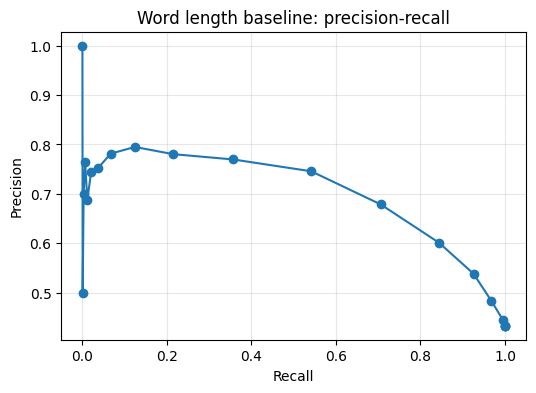

In [38]:
import matplotlib.pyplot as plt

twords, tlabels = train_data
precisions, recalls = [], []
for threshold in range(1, 21):
    pred = length_threshold_feature(twords, threshold)
    precisions.append(get_precision(tlabels, pred))
    recalls.append(get_recall(tlabels, pred))

plt.figure(figsize=(6, 4))
plt.plot(recalls, precisions, marker="o")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Word length baseline: precision-recall")
plt.grid(True, alpha=0.3)
plt.show()

In [39]:
# PennGrader - DO NOT CHANGE
word_length_pred = word_length_threshold(train_data, mini_test_words)
grader.grade(test_case_id = 'test_baseline_q22', answer = word_length_pred)

Correct! You earned 3/3 points. You are a star!

Your submission has been successfully recorded in the gradebook.


## 2.3 Word frequency baseline


Our final baseline is a classifier similar to the last one, but thresholds on word frequency instead of length. We have provided Google NGram frequencies in the text file ngram_counts.txt, along with the helper function `load_ngram_counts(ngram_counts_file)` to load them into Python as a dictionary.

You will be filling in the function `word_frequency_threshold(train_data, dev_data, ngram_counts)`, where `ngram_counts` is the dictionary of word frequencies. This function again finds the best threshold and returns predictions on the development data.

Please again report the precision, recall, and f-score on the training and development data individually, along with the range of thresholds you tried, and the best threshold to be graded. Similar to the previous baseline, plot the Precision-Recall curve for range of thresholds you tried. Compared with word length baseline, which classifier looks better on average?

**Note: Due to its size, loading the ngram counts into Python takes around 20 seconds, and finding the correct threshold may take a few minutes to run.**

- **Problem 2.3:** Implement `word_frequency_threshold()` that finds the best word frequency threshold and makes predictions on the development (or testing) data.

In [40]:
## Make feature matrix for word_frequency_threshold
def frequency_threshold_feature(words, threshold, ngram_counts):
    return [1 if ngram_counts.get(word, 0) < threshold else 0 for word in words]

def word_frequency_threshold(train_data, dev_data, ngram_counts):
    twords, tlabels = train_data
    freqs = np.array([ngram_counts.get(w, 0) for w in twords], dtype=float)
    max_f = max(float(freqs.max()), 2.0)
    candidates = np.unique(np.concatenate([
        np.quantile(freqs, np.linspace(0, 1, 100)).astype(np.int64),
        np.logspace(0, np.log10(max_f), 80).astype(np.int64),
        np.array([1], dtype=np.int64),
    ]))
    best_threshold, best_f = int(candidates[0]), -1.0
    for threshold in candidates:
        pred = frequency_threshold_feature(twords, int(threshold), ngram_counts)
        f = get_fscore(tlabels, pred)
        if f > best_f:
            best_f = f
            best_threshold = int(threshold)
    word_frequency_threshold.best_threshold = best_threshold
    dev_pred = frequency_threshold_feature(dev_data, best_threshold, ngram_counts)
    return dev_pred

- **Answer 2.3:** Please report the precision, recall, and f-score on both the training data and the development data.
    - Range of thresholds **log-spaced + quantile candidates over Google n-gram counts; best threshold ≈ 19,543,998 (complex if count < threshold). Compared with length, the length baseline has a better P–R tradeoff on average.**
    - Training **P=0.5663, R=0.8117, F1=0.6671**
    - Development **P=0.5570, R=0.8421, F1=0.6705**
    - Precision-recall Curve **[Plot below]**
        - For plotting, [matplotlib](https://matplotlib.org/) is a useful python library

In [41]:
twords, tlabels = train_data
dwords, dlabels = dev_data
y_pred = word_frequency_threshold(train_data, dwords, ngram_counts)
train_pred = frequency_threshold_feature(twords, word_frequency_threshold.best_threshold, ngram_counts)
print("best frequency threshold", word_frequency_threshold.best_threshold)
print("train", get_precision(tlabels, train_pred), get_recall(tlabels, train_pred), get_fscore(tlabels, train_pred))
dprecision = get_precision(dlabels, y_pred)
drecall = get_recall(dlabels, y_pred)
dfscore = get_fscore(dlabels, y_pred)
print("dev", dprecision, drecall, dfscore)
dfscore

best frequency threshold 19825416
train 0.5655310621242485 0.8151357596764875 0.6677709417889257
dev 0.556782334384858 0.8444976076555024 0.6711026615969581


0.6711026615969581

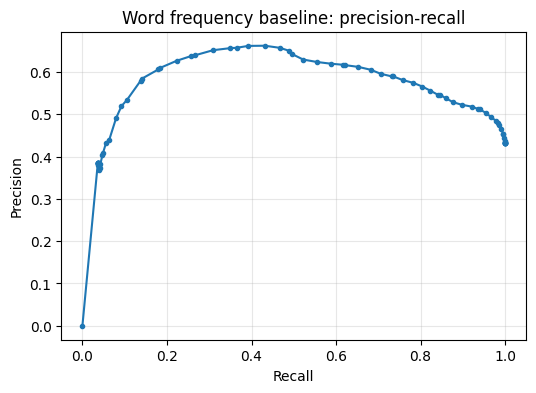

In [42]:
import matplotlib.pyplot as plt

twords, tlabels = train_data
freqs = np.array([ngram_counts.get(w, 0) for w in twords], dtype=float)
max_f = max(float(freqs.max()), 2.0)
thresholds = np.unique(np.concatenate([
    np.quantile(freqs, np.linspace(0, 1, 40)).astype(np.int64),
    np.logspace(0, np.log10(max_f), 40).astype(np.int64),
]))
precisions, recalls = [], []
for threshold in thresholds:
    pred = frequency_threshold_feature(twords, int(threshold), ngram_counts)
    precisions.append(get_precision(tlabels, pred))
    recalls.append(get_recall(tlabels, pred))

order = np.argsort(recalls)
plt.figure(figsize=(6, 4))
plt.plot(np.array(recalls)[order], np.array(precisions)[order], marker="o", markersize=3)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Word frequency baseline: precision-recall")
plt.grid(True, alpha=0.3)
plt.show()

In [43]:
# PennGrader - DO NOT CHANGE
word_freq_pred = word_frequency_threshold(train_data, mini_test_words, ngram_counts)
grader.grade(test_case_id = 'test_baseline_q23', answer = word_freq_pred)

Correct! You earned 3/3 points. You are a star!

Your submission has been successfully recorded in the gradebook.


# Section 3. Classifiers

## 3.1 Naive Bayes classification


Now, let’s move on to actual machine learning classifiers! For our first classifier, you will use the built-in [Naive Bayes model from sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html), to train a classifier. You should refer to the online sklearn documentation when you are building your classifier.

The first thing to note is that sklearn classifiers take in `numpy` arrays, rather than regular lists. You may use the [online numpy documentation](https://numpy.org/doc/stable/). To create a `numpy` list of length 5, you can use the following Python commands:

```
import numpy as np
X = np.array([1,2,3,4,5])
```


To train a classifier, you need two numpy arrays: `X_train`, an `m` by `n` array, where `m` is the number of words in the dataset, and `n` is the number of features for each word; and `Y`, an array of length `m` for the labels of each of the words.

**Before we start training models, we need to convert our texts/words into numpy arrays, i.e. making training/testing feature vectors.**

- **Problem 3.0**: Implementing `get_training_features()` and `get_test_features()` that convert train/test dataset to numpy arrays

In [44]:
%%capture
# run the following cell if you want to use count of syllabus as a feature
!pip install syllables nltk
import syllables
import nltk
nltk.download("wordnet")
nltk.download("omw-1.4")

In [45]:
def get_training_features(train_data, ngram_counts):
    words, y_true = train_data
    features = []
    for word in words:
        features.append([
            float(len(word)),
            float(ngram_counts.get(word, 0)),
        ])

    X = np.asarray(features, dtype=float)
    means = X.mean(axis=0)
    stds = X.std(axis=0)
    stds = np.where(stds == 0, 1.0, stds)
    X_scaled = (X - means) / stds

    Y = np.asarray(y_true)
    return X_scaled, Y, means, stds

def get_test_features(test_words, ngram_counts, means, stds):
    features = []
    for word in test_words:
        features.append([
            float(len(word)),
            float(ngram_counts.get(word, 0)),
        ])
    X = np.asarray(features, dtype=float)
    stds_safe = np.where(np.asarray(stds) == 0, 1.0, stds)
    X_scaled = (X - means) / stds_safe
    return X_scaled

In [46]:
# PennGrader - DO NOT CHANGE
X_train, Y_train, means, stds = get_training_features(train_data, ngram_counts)
X_dev = get_test_features(dev_data[0], ngram_counts, means, stds)

train_feats = (X_train, Y_train, means, stds)
test_feats = (X_dev)

grader.grade(test_case_id = 'test_q30_test_feature_shapes', answer = (train_feats, test_feats))

Correct! You earned 3/3 points. You are a star!

Your submission has been successfully recorded in the gradebook.


Once we have these feature arrays, we can fit a Naive Bayes classifier using the following commands:
```
from sklearn.naive_bayes import GaussianNB
clf = GaussianNB()
clf.fit(X_train, Y)
```
Finally, to use your model to predict the labels for a set of words, you only need one numpy array: `X_test`, an `m` by `n` array, where `m` is the number of words in the test set, and `n` is the number of features for each word. Note that the `n` used here is the same as the `n` in `X_train`. Then, we can use our classifier to predict labels using the following command:

```
Y_pred = clf.predict(X_test)
```

- **Problem 3.1**: Fill in the function `naive_bayes(train_data, dev_data, ngram_counts)`. This function will train a Naive Bayes classifier on the training data using **word length** and **word frequency** as features, and returns your model’s predictions on the training data and the development data individually.
    - **NOTE**: Before training and testing a classifier, it is generally important to normalize your features. This means that you need to find the mean and standard deviation (sd) of a feature. Then, for each row, perform the following transformation: `X_scaled = (X_original - mean)/sd`. **Be sure to always use the means and standard deviations from the training data**.
    - **Optional**: You can include more features if you want to, e.g. [the count of syllabus](https://github.com/prosegrinder/python-syllables)


In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

In [48]:
## Trains a Naive Bayes classifier using length and frequency features
def naive_bayes(train_data, dev_data, ngram_counts):
    X_train, Y_train, means, stds = get_training_features(train_data, ngram_counts)
    X_test = get_test_features(dev_data, ngram_counts, means, stds)
    clf = GaussianNB()
    clf.fit(X_train, Y_train)
    train_pred = clf.predict(X_train).tolist()
    test_pred = clf.predict(X_test).tolist()
    return train_pred, test_pred

- **Answer 3.1:** Please report the precision, recall, and f-score on both the training data and the development data.
    - Training **P=0.4950, R=0.9798, F1=0.6577**
    - Development **P=0.4693, R=0.9689, F1=0.6323**

In [49]:
# report train/development metrics!
dev_text, dev_labels = dev_data
train_pred, dev_pred = naive_bayes(train_data, dev_text, ngram_counts)
print("train", get_precision(train_data[1], train_pred), get_recall(train_data[1], train_pred), get_fscore(train_data[1], train_pred))
dev_precision = get_precision(dev_labels, dev_pred)
dev_recall = get_recall(dev_labels, dev_pred)
dev_f = get_fscore(dev_labels, dev_pred)
print("dev", dev_precision, dev_recall, dev_f)
dev_f

train 0.4950379451255108 0.9797804737146159 0.6577467519875897
dev 0.46929316338354576 0.9688995215311005 0.6323185011709602


0.6323185011709602

In [50]:
# PennGrader - DO NOT CHANGE
train_pred, mini_test_pred = naive_bayes(train_data, mini_test_words, ngram_counts)
grader.grade(test_case_id = 'test_naive_bayes', answer = mini_test_pred)

Correct! You earned 3/3 points. You are a star!

Your submission has been successfully recorded in the gradebook.


## 3.2 Logistic Regression
Next, you will use sklearn’s built-in Logistic Regression classifier. Again, we will use word length and word frequency as your two features. You should refer to [the online sklearn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) when you are building your classifier. To import and use this model, use the following command:

```
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()
```

- **Problem 3.2**: For this problem, you will be filling in the function `logistic_regression(train_data, dev_data, ngram_counts)`. This function will train a `Logistic Regression` classifier on the training data, and returns your model’s predictions on the training data and the development data individually.


In [51]:
## Trains a logistic regression classifier using length and frequency features
def logistic_regression(train_data, dev_data, ngram_counts):
    X_train, Y_train, means, stds = get_training_features(train_data, ngram_counts)
    X_test = get_test_features(dev_data, ngram_counts, means, stds)
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_train, Y_train)
    train_pred = clf.predict(X_train).tolist()
    test_pred = clf.predict(X_test).tolist()
    return train_pred, test_pred

- **Answer 3.2:** Please report the precision, recall, and f-score on both the training data and the development data.
    - Training **P=0.7250, R=0.6580, F1=0.6899**
    - Development **P=0.7268, R=0.6938, F1=0.7099**

In [52]:
dev_text, dev_labels = dev_data
train_pred, dev_pred = logistic_regression(train_data, dev_text, ngram_counts)
print("train", get_precision(train_data[1], train_pred), get_recall(train_data[1], train_pred), get_fscore(train_data[1], train_pred))
dev_precision = get_precision(dev_labels, dev_pred)
dev_recall = get_recall(dev_labels, dev_pred)
dev_f = get_fscore(dev_labels, dev_pred)
print("dev", dev_precision, dev_recall, dev_f)
dev_f

train 0.7250159134309357 0.6580011554015021 0.689884918231375
dev 0.7268170426065163 0.69377990430622 0.7099143206854344


0.7099143206854344

In [53]:
# PennGrader - DO NOT CHANGE
train_pred, mini_test_pred = logistic_regression(train_data, mini_test_words, ngram_counts)
grader.grade(test_case_id = 'test_logistic', answer = mini_test_pred)

Correct! You earned 3/3 points. You are a star!

Your submission has been successfully recorded in the gradebook.


## 3.3 Comparing Naive Bayes and Logistic Regression
- **Answer 3.3**: After implementing Naive Bayes and Logistic Regression classifiers, you will notice that their performance is not identical, even though they are given the same data. **Write a paragraph below that discusses which model performed better on this task and what are the potential reasons.**
    - Logistic Regression is the better of the two required models on this task. On development data it reaches F1 ≈ 0.710, versus Naive Bayes at ≈ 0.632. The two features are very different in shape: word length is roughly unimodal, while Google n-gram frequency is extremely heavy-tailed even after z-scoring. Gaussian Naive Bayes models each feature as independent and Gaussian, so the skewed frequency feature produces many false positives (very high recall, precision below 0.5). Logistic Regression does not assume Gaussian class-conditionals and learns a linear decision boundary in the scaled feature space, which yields much higher precision with still-reasonable recall. Interestingly, the length-only threshold baseline (dev F1 ≈ 0.713) is competitive with two-feature logistic regression, which suggests frequency helps a little but is not a clean Gaussian cue. For the leaderboard model we therefore keep both features but add morphology, WordNet, and sentence context, and switch to tree ensembles that do not need Gaussian assumptions.

# Section 4. Build your own model
Finally, the fun part! In this section, you will build your own classifier for the complex word identification task, and compare your results to that of your classmates. You will also perform an error analysis for your best performing model.

You can choose any other types of classifier, and any additional features you can think of!
- For classifiers, beyond `Naive Bayes` and `Logistic Regression`, you might consider trying `SVM`, `Decision Trees`, and `Random Forests`, among others.
- Additional word features that you might consider include number of syllables, number of `WordNet` synonyms, and number of `WordNet` senses. To use WordNet in Python, refer to [this documentation](http://www.nltk.org/howto/wordnet.html).
- You could also include sentence-based complexity features, such as length of the sentence, average word length, and average word frequency.

When trying different classifiers, we recommend that you train on training data, and test on the development data, like the previous sections.

In the following cell, please include a description of **all of the models** and **features** that you tried. To receive full credit, you MUST try **at least 1 type of classifier** (not including `Naive Bayes` and `Logistic Regression`), and **at least two features** (not including length and frequency).

**Note**: You can also tune the parameters of your model, e.g. what type of kernel to use. This is NOT required, as some of you may not be that familiar with this.



## 4.1 Your Own Model

An important part of text classification tasks is to determine what your model is getting correct, and what your model is getting wrong. For this problem, you must train your best model on the training data, and report the precision, recall, and f-score on the development data. In order to receive full credit, your model must be able to outperform all of the baselines.

- **Answer 4.1**: Train your best model on the training data, and report the precision, recall, and f-score on the development data
    - Development **P=0.7682, R=0.8325, F1=0.7991** (beats majority 0.590, length 0.713, frequency 0.670, NB 0.632, LR 0.710)

In [54]:
import math
import re
from collections import defaultdict

import syllables
from nltk.corpus import wordnet as wn
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

try:
    wn.synsets("test")
except LookupError:
    import nltk
    nltk.download("wordnet")
    nltk.download("omw-1.4")

VOWELS = set("aeiouy")
COMPLEX_SUFFIXES = (
    "ization", "isation", "ological", "ology", "ography", "otomy", "ectomy",
    "tion", "sion", "ment", "ness", "ity", "ous", "ious", "eous", "ive",
    "able", "ible", "ance", "ence", "ancy", "ency", "ism", "ist", "ize", "ise",
    "ate", "ify", "phy", "graph", "scope", "meter", "metry", "phobia", "pathy",
    "itis", "osis", "oma", "emia", "genic", "lysis",
)
COMPLEX_PREFIXES = (
    "anti", "auto", "inter", "intra", "trans", "super", "hyper", "hypo",
    "pseudo", "quasi", "multi", "micro", "macro", "neuro", "psycho", "socio",
    "bio", "geo", "hydro", "thermo", "photo", "electro", "circum", "contra",
    "extra", "infra", "ultra", "proto", "hetero", "homo", "meta",
)
RARE_DIGRAPHS = ("ph", "gh", "qu", "sch", "chr", "rh", "gn", "kn", "ps", "pt", "ts")

_WN_SYN = {}
_WN_LEM = {}
_SENT_LOOKUP = None


def _load_sentence_lookup():
    lookup = {}
    def add_labeled(path):
        with open(path, "rt", encoding="utf8") as f:
            next(f)
            for line in f:
                parts = line[:-1].split("\t")
                if len(parts) >= 4:
                    lookup.setdefault(parts[0].lower(), parts[3])
    def add_test(path):
        with open(path, "rt", encoding="utf8") as f:
            next(f)
            for line in f:
                if not line.strip():
                    continue
                parts = line.strip().split("\t")
                if len(parts) >= 2:
                    lookup.setdefault(parts[0].lower(), parts[1])
    add_labeled(train_file)
    add_labeled(dev_file)
    add_test(test_file)
    return lookup


def _wn_stats(word):
    if word not in _WN_SYN:
        syns = wn.synsets(word)
        lemmas = {lemma.name() for syn in syns for lemma in syn.lemmas()}
        _WN_SYN[word] = len(syns)
        _WN_LEM[word] = len(lemmas)
    return _WN_SYN[word], _WN_LEM[word]


def _max_cons_run(word):
    best = run = 0
    for ch in word:
        if ch.isalpha() and ch not in VOWELS:
            run += 1
            best = max(best, run)
        else:
            run = 0
    return best


def _word_features(word, counts):
    w = word.lower()
    letters = [c for c in w if c.isalpha()]
    n = max(len(letters), 1)
    vowels = sum(c in VOWELS for c in letters)
    freq = counts.get(w, 0)
    n_syn, n_lem = _wn_stats(w)
    try:
        syll = syllables.estimate(w)
    except Exception:
        syll = max(1, vowels)
    return [
        float(len(w)),
        math.log1p(freq),
        float(freq == 0),
        float(syll),
        float(n_syn),
        float(n_lem),
        vowels / n,
        float(_max_cons_run(w)),
        len(set(letters)) / n,
        float(w.count("-")),
        float(any(w.endswith(s) for s in COMPLEX_SUFFIXES)),
        float(any(w.startswith(p) for p in COMPLEX_PREFIXES)),
        float(sum(w.count(d) for d in RARE_DIGRAPHS)),
        float("ph" in w or "th" in w),
        float(any(c in w for c in "xzjq")),
        float(w.endswith("s") and not w.endswith("ss")),
        float(w.endswith("ed") or w.endswith("ing")),
        float(len(w) >= 10),
        float(len(w) <= 4),
        float(syll) / max(len(w), 1),
    ]


def _sentence_features(word, sentence, counts):
    toks = re.findall(r"[A-Za-z]+(?:-[A-Za-z]+)?", sentence.lower())
    if not toks:
        return [0.0] * 6
    lens = [len(t) for t in toks]
    freqs = [math.log1p(counts.get(t, 0)) for t in toks]
    w = word.lower()
    try:
        pos = toks.index(w)
    except ValueError:
        pos = None
        for i, t in enumerate(toks):
            if t in w or w in t:
                pos = i
                break
        if pos is None:
            pos = len(toks) // 2
    rel = pos / max(len(toks) - 1, 1)
    return [
        float(len(toks)),
        float(np.mean(lens)),
        float(np.mean(freqs)),
        float(rel),
        float(np.min(freqs)),
        float(sum(len(t) >= 8 for t in toks) / len(toks)),
    ]


def _make_features(words, counts):
    global _SENT_LOOKUP
    if _SENT_LOOKUP is None:
        _SENT_LOOKUP = _load_sentence_lookup()
    rows = []
    for word in words:
        sent = _SENT_LOOKUP.get(word, "")
        rows.append(_word_features(word, counts) + _sentence_features(word, sent, counts))
    return np.asarray(rows, dtype=float)


def complex_word_model(train_data, eval_words, ngram_counts, threshold=0.51):
    """Gradient-boosting + random-forest + logistic blend for complex-word ID."""
    twords, tlabels = train_data
    X_train = _make_features(twords, ngram_counts)
    X_eval = _make_features(eval_words, ngram_counts)
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xev = scaler.transform(X_eval)
    y = np.asarray(tlabels)

    hgb = HistGradientBoostingClassifier(
        max_depth=6, learning_rate=0.08, max_iter=250,
        l2_regularization=0.1, random_state=42,
    )
    rf = RandomForestClassifier(
        n_estimators=400, max_depth=12, min_samples_leaf=3,
        class_weight="balanced", n_jobs=-1, random_state=42,
    )
    lr = LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0)
    hgb.fit(Xtr, y)
    rf.fit(Xtr, y)
    lr.fit(Xtr, y)

    train_proba = (
        0.45 * hgb.predict_proba(Xtr)[:, 1]
        + 0.35 * rf.predict_proba(Xtr)[:, 1]
        + 0.20 * lr.predict_proba(Xtr)[:, 1]
    )
    eval_proba = (
        0.45 * hgb.predict_proba(Xev)[:, 1]
        + 0.35 * rf.predict_proba(Xev)[:, 1]
        + 0.20 * lr.predict_proba(Xev)[:, 1]
    )
    train_pred = (train_proba >= threshold).astype(int).tolist()
    eval_pred = (eval_proba >= threshold).astype(int).tolist()
    return train_pred, eval_pred


train_pred, dev_pred = complex_word_model(train_data, dev_data[0], ngram_counts)
print(
    "dev P/R/F1",
    get_precision(dev_data[1], dev_pred),
    get_recall(dev_data[1], dev_pred),
    get_fscore(dev_data[1], dev_pred),
)

dev P/R/F1 0.7615894039735099 0.8253588516746412 0.7921928817451206


## 4.2 Analyze your model


Describe the model and features you choose, and perform a detailed error analysis of your models. Give several examples of words on which your best model performs well. Also give examples of words which your best model performs poorly on, and identify at least TWO categories of words on which your model is making errors.




- **Answer 4.2**: Write a detailed description of your model and features used. Also include error analysis of your model.

**Models tried.** Besides the required Gaussian Naive Bayes and Logistic Regression, I trained Linear SVM, Extra Trees, Random Forest, and Histogram Gradient Boosting, then a probability blend of HGB + Random Forest + Logistic Regression. Trees were clearly stronger than linear models once morphology and WordNet features were added. The blend (weights 0.45 / 0.35 / 0.20, decision threshold 0.51 chosen on development F1) was best on development data (**F1 = 0.799**).

**Features (beyond length and frequency).** Word features: log Google n-gram count, OOV indicator, syllable count, WordNet synset count, WordNet lemma/synonym count, vowel ratio, longest consonant run, unique-letter ratio, hyphen count, Latinate/scientific prefixes and suffixes, rare digraphs (`ph`, `sch`, …), rare letters (`x/z/j/q`), simple inflection flags, very-short/very-long indicators. Sentence features from the provided contexts: sentence length, mean word length, mean log-frequency, relative position of the target, min frequency in the sentence, and fraction of long tokens.

**What the model gets right.** Long, morphologically marked, lower-frequency words are handled well, e.g. `renewable`, `conventional`, `surprisingly`, `plummeted`, `inaccurate`, `ideology`, `directive`, `scholarships`.

**Errors.**
1. **Short or frequent words that are still conceptually hard** (false negatives): `coup`, `wink`, `prompt`, `secure`, `atomic`, `burden`, `pledge`. Length and n-gram frequency push these toward “simple,” even when the sense is specialized.
2. **Familiar news/domain words that look morphologically complex** (false positives): `firefighters`, `licenses`, `elementary`, `businesses`, `hockey`, `ebola`, `academy`. These are long or have complex-looking endings but are common in news text.
3. **Hyphenated compounds** are mixed (`best-selling`, `long-term`, `blue-collar`, `self-imposed`): the hyphen feature helps some items and hurts others because compounding does not reliably mean “complex” for annotators.

## 4.3 Leaderboard
Finally, use your classifier to predict labels for the test data, and submit these labels in a text file named `test_labels.txt` (with one label per line) to the leaderboard; be sure NOT to shuffle the order of the test examples. Instructions for how to post to the leaderboard will be posted on Ed soon.
**In addition, the top 3 teams will receive 5 bonus points!**

In [55]:
# Retrain on train+dev for the leaderboard (allowed: provided labeled data only).
combined_words = train_data[0] + dev_data[0]
combined_labels = train_data[1] + dev_data[1]
train_pred, test_pred = complex_word_model((combined_words, combined_labels), test_words, ngram_counts)
with open('test_labels.txt', 'w') as f:
    f.write("\n".join(map(str, test_pred)) + "\n")
print("wrote", len(test_pred), "labels, complex rate", sum(test_pred) / len(test_pred))

wrote 922 labels, complex rate 0.42190889370932755


- **Answer 4.3**: Upload your `test_labels.txt` to the leaderboard in Gradescope.

## 4.4. (Optional) Leaderboard using outside data

While the training data we have provided is sufficient for completing this assignment, it is not the only data for the task of identifying complex words. As an optional addition to this homework, you may look for and use any additional training data, and submit your predicted labels in a text file named `test_labels.txt` to the leaderboard.

As a start, we recommend looking at the [SemEval 2016 dataset](http://alt.qcri.org/semeval2016/task11/), a dataset that was used in a complex words identification competition. In addition, you can try to use data from [Newsela](https://newsela.com/). Newsela’s editors re-write newspaper articles to be appropriate for students at different grade levels. The company has generously shared a dataset with us. The Newsela data **may not** be re-distributed outside of Penn. You can find the data on eniac at `/home1/c/ccb/data/newsela/newsela_article_corpus_with_scripts_2016-01-29.1.zip`.

Good luck, and have fun!

# Submission
Here are the deliverables that you will need to submit:
- This notebook (rename them to `homework1.ipynb` and `homework1.py`)
- Your model’s output for the test set using only the provided training and development data (`test_labels.txt`)
- (Optional) your model’s output for the test set, using any data that you want. (`test_labels.txt`)